# # 04 · Correlation and factor analysis (M4)
#
# **Questions:** Which pollutants move together? Can the four pollutants be summarised by a smaller number
# of hidden (latent) factors, e.g. a "particulate / dust" factor and a "combustion / gas" factor?
#
# Variables: log SO2, log NO2, log PM10, log PM2.5 (log because M2 showed the raw values are right-skewed).
# **Honest limitation up front:** with only 4 observed variables, factor analysis can support at most one
# well-identified common factor under maximum likelihood (2 factors leave −1 degrees of freedom).
# We therefore fit a 1-factor ML model, a 2-factor principal-axis model with varimax rotation as an
# exploratory comparison, and PCA as a descriptive check.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import src.compat  # sklearn compatibility shim for factor_analyzer
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display

from src.style import apply_style, save_fig, save_table, STATE_COLORS, LABELS, ACCENT, FIGSIZE, DIV_CMAP
from src.data import load_clean, POLLUTANTS, STATE_ORDER

apply_style()
pd.set_option("display.width", 160)
df = load_clean()
LOGS = [f"log_{p}" for p in POLLUTANTS]
NICE = {"log_SO2": "SO2", "log_NO2": "NO2", "log_PM10": "PM10", "log_PM25": "PM2.5",
        "SO2": "SO2", "NO2": "NO2", "PM10": "PM10", "PM25": "PM2.5"}
X = df[LOGS].rename(columns=NICE)

# ## 1. Correlation matrices (Pearson on logs, Spearman on raw values)

,SO2,NO2,PM10,PM2.5
SO2,1.000,0.262,0.336,0.223
NO2,0.262,1.000,0.279,0.385
PM10,0.336,0.279,1.000,0.755
PM2.5,0.223,0.385,0.755,1.000


,SO2,NO2,PM10,PM2.5
SO2,1.000,0.258,0.262,0.076
NO2,0.258,1.000,0.166,0.243
PM10,0.262,0.166,1.000,0.698
PM2.5,0.076,0.243,0.698,1.000


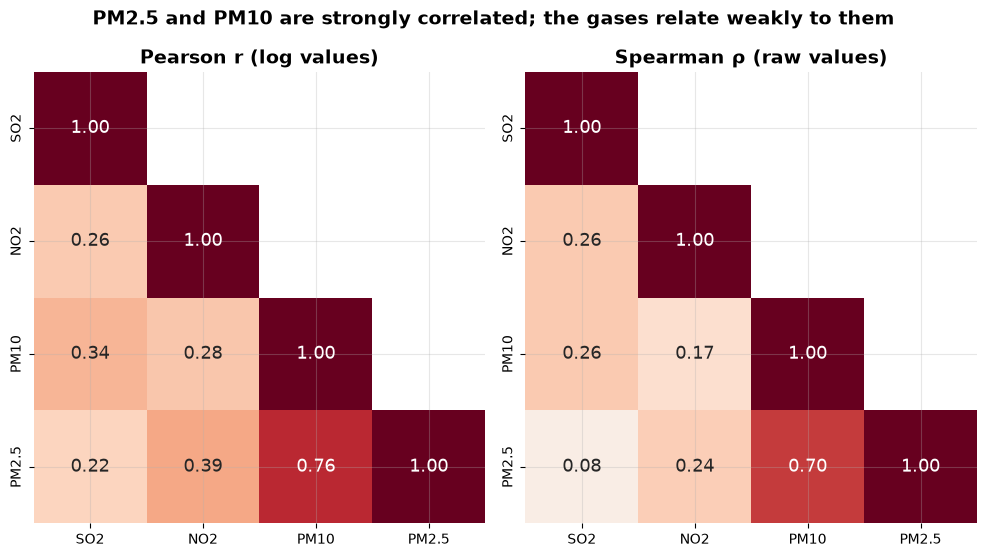

In [2]:
pear = X.corr(method="pearson")
spear = df[POLLUTANTS].rename(columns=NICE).corr(method="spearman")
n = len(X)
pvals = pd.DataFrame(index=pear.index, columns=pear.columns, dtype=float)
for a in pear.index:
    for b in pear.columns:
        pvals.loc[a, b] = stats.pearsonr(X[a], X[b]).pvalue if a != b else 0
display(pear.round(3)); display(spear.round(3))
save_table(pear.round(4), "m4_corr_pearson_log", index=True)
save_table(spear.round(4), "m4_corr_spearman", index=True)
save_table(pvals, "m4_corr_pearson_pvalues", index=True)

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
for ax, (m, title) in zip(axes, [(pear, "Pearson r (log values)"), (spear, "Spearman ρ (raw values)")]):
    mask = np.triu(np.ones_like(m, dtype=bool), k=1)
    sns.heatmap(m, mask=mask, annot=True, fmt=".2f", cmap=DIV_CMAP, vmin=-1, vmax=1, square=True,
                cbar=False, ax=ax, annot_kws={"size": 13})
    ax.set_title(title)
fig.suptitle("PM2.5 and PM10 are strongly correlated; the gases relate weakly to them", fontweight="bold", fontsize=14)
fig.tight_layout(); save_fig(fig, "m4_correlation_heatmap"); plt.show()

# ### Correlations within each state
# Pooling states can create or hide correlations (Simpson's paradox), so we check within each state.

In [3]:
within = []
for s in STATE_ORDER:
    c = df.loc[df.state == s, LOGS].rename(columns=NICE).corr()
    for a, b in [("PM10", "PM2.5"), ("NO2", "PM2.5"), ("NO2", "PM10"), ("SO2", "NO2"), ("SO2", "PM2.5"), ("SO2", "PM10")]:
        within.append({"state": s, "pair": f"{a}–{b}", "r": c.loc[a, b]})
within = pd.DataFrame(within).pivot(index="pair", columns="state", values="r")
within["pooled"] = [pear.loc[p.split("–")[0], p.split("–")[1]] for p in within.index]
display(within.round(3))
save_table(within.round(4), "m4_corr_within_state", index=True)

state,Gujarat,Odisha,West Bengal,pooled
pair,,,,
NO2–PM10,0.209,0.020,0.772,0.279
NO2–PM2.5,0.039,0.089,0.838,0.385
PM10–PM2.5,0.187,0.753,0.944,0.755
SO2–NO2,0.615,0.211,0.638,0.262
SO2–PM10,-0.036,0.358,0.623,0.336
SO2–PM2.5,0.352,0.454,0.745,0.223


WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m4_corr_within_state.csv')

# ## 2. Suitability for factor analysis: KMO and Bartlett
# - **Bartlett's test of sphericity** — H0: the correlation matrix is an identity matrix (no shared variance).
# - **KMO** — share of variance that might be common; > 0.6 acceptable, > 0.8 good.

In [4]:
Z = StandardScaler().fit_transform(X)
chi2, bp = calculate_bartlett_sphericity(X)
kmo_per, kmo_total = calculate_kmo(X)
suit = pd.DataFrame({"KMO (per variable)": kmo_per}, index=X.columns)
display(suit.round(3))
print(f"Overall KMO = {kmo_total:.3f}")
print(f"Bartlett chi² = {chi2:.1f}, df = {X.shape[1]*(X.shape[1]-1)//2}, p = {bp:.3g}")
suit.loc["Overall", "KMO (per variable)"] = kmo_total
suit["Bartlett chi2"] = chi2; suit["Bartlett p"] = bp
save_table(suit.round(4), "m4_kmo_bartlett", index=True)

,KMO (per variable)
SO2,0.644
NO2,0.688
PM10,0.555
PM2.5,0.551


Overall KMO = 0.579
Bartlett chi² = 4422.7, df = 6, p = 0


WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m4_kmo_bartlett.csv')

# ## 3. How many factors? Eigenvalues, scree plot and parallel analysis
# Parallel analysis compares our eigenvalues with those of random normal data of the same size
# (95th percentile of 500 simulations, seed 42). Keep factors whose eigenvalue beats the random one.

,component,eigenvalue,% variance,cumulative %,parallel 95th pct,retain (Kaiser >1),retain (parallel)
0,1,2.170,54.241,54.241,1.058,True,True
1,2,0.857,21.428,75.668,1.023,False,False
2,3,0.752,18.789,94.457,1.002,False,False
3,4,0.222,5.543,100.000,0.982,False,False


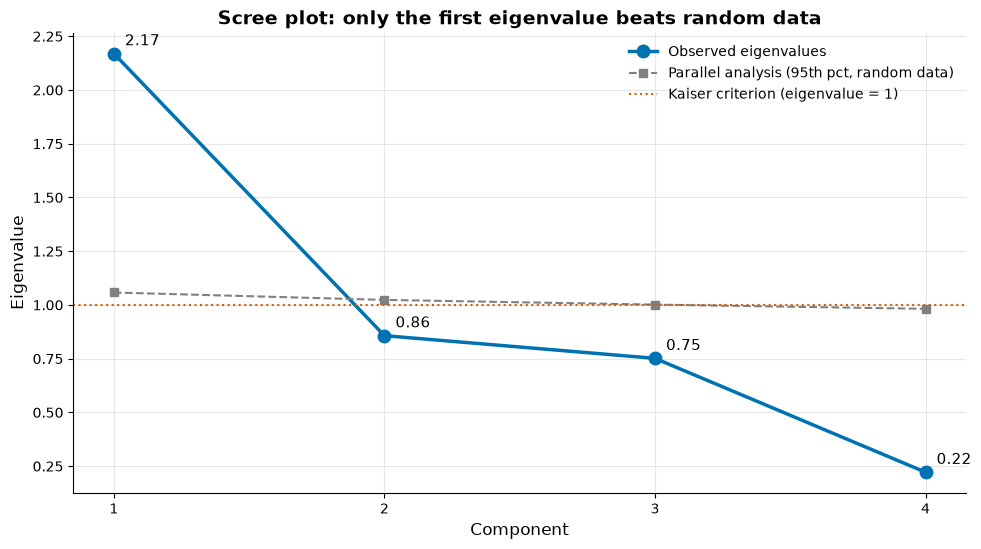

In [5]:
eig = np.linalg.eigvalsh(np.corrcoef(Z, rowvar=False))[::-1]
rng = np.random.default_rng(42)
sims = np.array([np.linalg.eigvalsh(np.corrcoef(rng.standard_normal(Z.shape), rowvar=False))[::-1] for _ in range(500)])
pa95 = np.percentile(sims, 95, axis=0)
eig_tbl = pd.DataFrame({"component": range(1, 5), "eigenvalue": eig, "% variance": 100 * eig / eig.sum(),
                        "cumulative %": 100 * np.cumsum(eig) / eig.sum(), "parallel 95th pct": pa95,
                        "retain (Kaiser >1)": eig > 1, "retain (parallel)": eig > pa95})
display(eig_tbl.round(3))
save_table(eig_tbl.round(4), "m4_eigenvalues_parallel")

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(range(1, 5), eig, "o-", color="#0072B2", lw=2.5, ms=9, label="Observed eigenvalues")
ax.plot(range(1, 5), pa95, "s--", color="grey", lw=1.5, label="Parallel analysis (95th pct, random data)")
ax.axhline(1, color=ACCENT, ls=":", label="Kaiser criterion (eigenvalue = 1)")
for i, e in enumerate(eig):
    ax.annotate(f"{e:.2f}", (i + 1, e), textcoords="offset points", xytext=(8, 6))
ax.set_xticks(range(1, 5)); ax.set_xlabel("Component"); ax.set_ylabel("Eigenvalue")
ax.set_title("Scree plot: only the first eigenvalue beats random data"); ax.legend()
fig.tight_layout(); save_fig(fig, "m4_scree_parallel"); plt.show()

# ## 4. Factor extraction
# ### 4a. One-factor maximum likelihood model (identified: df = 2)

In [6]:
fa1 = FactorAnalyzer(n_factors=1, method="ml", rotation=None).fit(Z)
sign = 1 if fa1.loadings_.sum() >= 0 else -1  # factor sign is arbitrary; orient so loadings are positive
load1 = pd.DataFrame(sign * fa1.loadings_, index=X.columns, columns=["F1"])
load1["communality"] = fa1.get_communalities()
load1["uniqueness"] = fa1.get_uniquenesses()
display(load1.round(3))
v1 = fa1.get_factor_variance()
print(f"Variance explained by F1: {100*v1[1][0]:.1f}%")
save_table(load1.round(4), "m4_loadings_1factor_ml", index=True)

,F1,communality,uniqueness
SO2,0.326,0.106,0.894
NO2,0.396,0.157,0.843
PM10,0.856,0.732,0.268
PM2.5,0.880,0.775,0.225


Variance explained by F1: 44.3%


WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m4_loadings_1factor_ml.csv')

# ### 4b. Two-factor principal-axis model with varimax rotation (exploratory)
# With 4 variables, 2 factors are not uniquely identified under ML, so we use principal-axis factoring and
# interpret cautiously.

In [7]:
fa2 = FactorAnalyzer(n_factors=2, method="principal", rotation="varimax").fit(Z)
load2 = pd.DataFrame(fa2.loadings_, index=X.columns, columns=["F1", "F2"])
load2["communality"] = fa2.get_communalities()
var2 = pd.DataFrame(fa2.get_factor_variance(), index=["SS loadings", "proportion var", "cumulative var"],
                    columns=["F1", "F2"])
display(load2.round(3)); display(var2.round(3))
save_table(load2.round(4), "m4_loadings_2factor_varimax", index=True)
save_table(var2.round(4), "m4_variance_2factor", index=True)

,F1,F2,communality
SO2,0.068,0.895,0.805
NO2,0.326,0.619,0.490
PM10,0.890,0.218,0.840
PM2.5,0.931,0.159,0.892


,F1,F2
SS loadings,1.770,1.257
proportion var,0.442,0.314
cumulative var,0.442,0.757


WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m4_variance_2factor.csv')

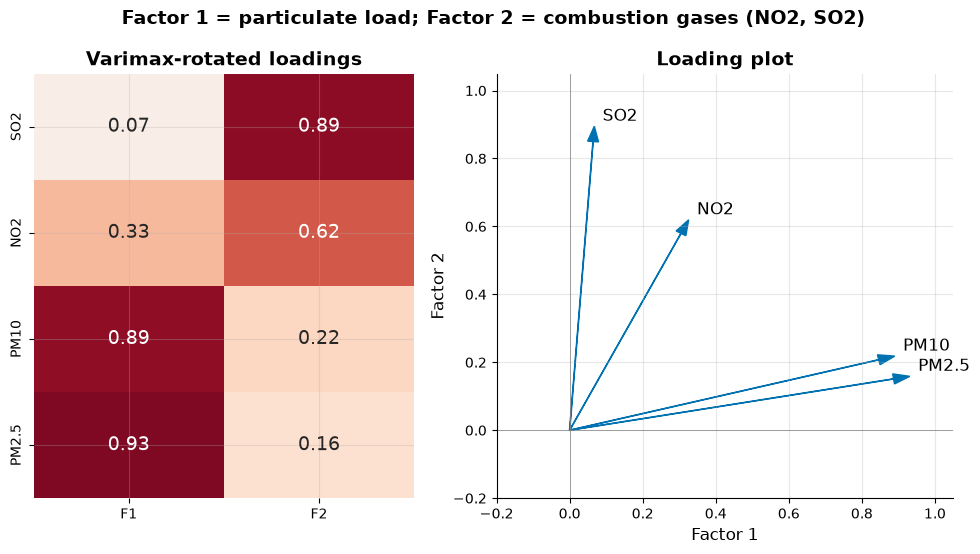

In [8]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1, 1.2]})
sns.heatmap(load2[["F1", "F2"]], annot=True, fmt=".2f", cmap=DIV_CMAP, vmin=-1, vmax=1, cbar=False, ax=axes[0],
            annot_kws={"size": 14})
axes[0].set_title("Varimax-rotated loadings")
ax = axes[1]
for v, (a, b) in load2[["F1", "F2"]].iterrows():
    ax.arrow(0, 0, a, b, head_width=.03, color="#0072B2", length_includes_head=True)
    ax.annotate(v, (a, b), textcoords="offset points", xytext=(6, 4), fontsize=12)
ax.set_xlim(-.2, 1.05); ax.set_ylim(-.2, 1.05); ax.axhline(0, color="grey", lw=.5); ax.axvline(0, color="grey", lw=.5)
ax.set_xlabel("Factor 1"); ax.set_ylabel("Factor 2"); ax.set_title("Loading plot")
fig.suptitle("Factor 1 = particulate load; Factor 2 = combustion gases (NO2, SO2)", fontweight="bold", fontsize=14)
fig.tight_layout(); save_fig(fig, "m4_factor_loadings"); plt.show()

# ### 4c. Factor structure within each state
# The pooled correlations hide very different patterns by state (section 1), so we check KMO and a
# one-factor ML model separately in each state.

In [9]:
rows = []
for s in STATE_ORDER:
    Xs = df.loc[df.state == s, LOGS].rename(columns=NICE)
    Zs = StandardScaler().fit_transform(Xs)
    _, kmo_s = calculate_kmo(Xs)
    chi_s, p_s = calculate_bartlett_sphericity(Xs)
    eig_s = np.linalg.eigvalsh(np.corrcoef(Zs, rowvar=False))[::-1]
    f = FactorAnalyzer(n_factors=1, method="ml", rotation=None).fit(Zs)
    row = {"state": s, "n": len(Xs), "KMO": kmo_s, "Bartlett chi2": chi_s, "Bartlett p": p_s,
           "eigenvalue 1": eig_s[0], "eigenvalue 2": eig_s[1], "% var F1": 100 * f.get_factor_variance()[1][0]}
    sg = 1 if f.loadings_.sum() >= 0 else -1
    row.update({f"loading {v}": sg * l for v, l in zip(Xs.columns, f.loadings_[:, 0])})
    rows.append(row)
by_state_fa = pd.DataFrame(rows).set_index("state")
display(by_state_fa.round(3))
save_table(by_state_fa.round(4), "m4_factor_by_state", index=True)

,n,KMO,Bartlett chi2,Bartlett p,eigenvalue 1,eigenvalue 2,% var F1,loading SO2,loading NO2,loading PM10,loading PM2.5
state,,,,,,,,,,,
Gujarat,1080,0.341,923.763,0.0,1.767,1.057,37.514,0.997,0.617,-0.035,0.352
Odisha,2060,0.601,2302.057,0.0,2.090,1.041,44.317,0.465,0.091,0.770,0.977
West Bengal,638,0.717,2797.070,0.0,3.292,0.425,78.685,0.744,0.840,0.946,0.998


WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m4_factor_by_state.csv')

# ## 5. PCA comparison

In [10]:
pca = PCA().fit(Z)
pca_load = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index=X.columns,
                        columns=[f"PC{i+1}" for i in range(4)])
pca_load.loc["% variance"] = 100 * pca.explained_variance_ratio_
display(pca_load.round(3))
save_table(pca_load.round(4), "m4_pca_loadings", index=True)

,PC1,PC2,PC3,PC4
SO2,0.550,0.709,-0.436,0.069
NO2,0.614,0.337,0.711,-0.070
PM10,0.863,-0.309,-0.237,-0.323
PM2.5,0.864,-0.382,0.009,0.328
% variance,54.241,21.428,18.789,5.543


WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m4_pca_loadings.csv')

# ## 6. Factor scores by state
# Scores from the 2-factor model are saved for M5 (to use as collinearity-free predictors).

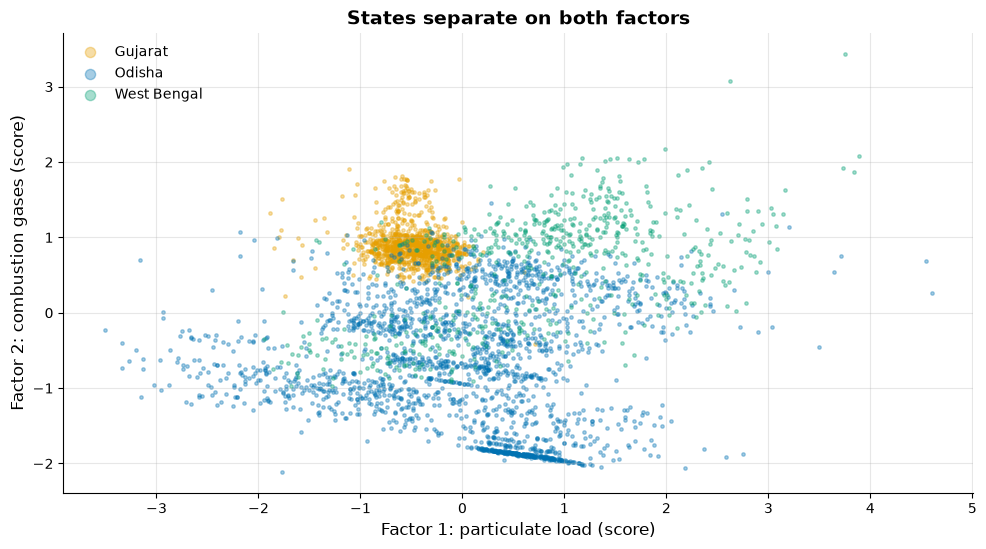

,F1_particulate,F2_gas
state,,
Gujarat,-0.49,0.90
Odisha,0.02,-0.65
West Bengal,0.76,0.57


In [11]:
scores = pd.DataFrame(fa2.transform(Z), columns=["F1_particulate", "F2_gas"], index=df.index)
out = pd.concat([df[["station", "state", "city", "date", "season"]], scores], axis=1)
save_table(out, "m4_factor_scores")
fig, ax = plt.subplots(figsize=FIGSIZE)
for s in STATE_ORDER:
    d = scores[df.state == s]
    ax.scatter(d.F1_particulate, d.F2_gas, s=6, alpha=.35, color=STATE_COLORS[s], label=s)
ax.set_xlabel("Factor 1: particulate load (score)"); ax.set_ylabel("Factor 2: combustion gases (score)")
ax.set_title("States separate on both factors"); ax.legend(markerscale=3)
fig.tight_layout(); save_fig(fig, "m4_factor_scores_by_state"); plt.show()
display(out.groupby("state")[["F1_particulate", "F2_gas"]].mean().round(2))

# ## 7. Conclusions (slides 9–10)
#
# 1. **Correlations.** The strongest pair is PM10–PM2.5 (Pearson r = 0.76 on logs, Spearman ρ = 0.70).
#    NO2 is moderately related to PM2.5 (r = 0.39); SO2 is weakly related to everything (r = 0.22–0.34).
#    All are significant at n = 3,778 but only the particulate pair is strong.
# 2. **Within states the picture differs:** in West Bengal all four pollutants rise and fall together
#    (r = 0.62–0.94), in Odisha only the two particulates do (r = 0.75), and Gujarat shows almost no
#    PM10–PM2.5 correlation (r = 0.19), again pointing to unusual Gujarat data.
# 3. **Suitability.** Bartlett's test rejects sphericity (χ² = 4,423, df = 6, p < 0.001), so the
#    variables share variance. But overall KMO = 0.58 is *mediocre* (just below the 0.6 guideline),
#    mainly because only four variables are available. Factor analysis is therefore exploratory.
# 4. **Number of factors.** Eigenvalues 2.17, 0.86, 0.75, 0.22. Kaiser (>1), the scree elbow and parallel
#    analysis all retain **one factor**, explaining 54% of the variance.
# 5. **The factor.** One-factor ML loadings: PM2.5 0.88, PM10 0.86, NO2 0.40, SO2 0.33. This is a
#    **"particulate pollution" factor**; the gases are mostly unique variance.
#    The exploratory two-factor varimax solution separates a **particulate factor** (PM2.5 0.93, PM10 0.89;
#    44% variance) from a **combustion-gas factor** (SO2 0.89, NO2 0.62; 31%), 76% in total. It is
#    interpretable but not statistically identified with 4 variables, so we present it as a description.
# 6. **By state.** West Bengal: KMO 0.72 and a single factor explains 79% of the variance with all loadings
#    > 0.74 — one shared driver (likely winter meteorology plus urban/industrial combustion). Odisha: KMO
#    0.60, a particulate factor. Gujarat: KMO 0.34, unsuitable for factor analysis.
# 7. PCA gives the same picture (PC1 54% with all positive loadings, PC2 contrasts gases vs particulates).
#    Factor scores were saved for M5 to use as uncorrelated predictors.